# Telecom Customer Churn Prediction — Simu Connect

**Role:** Data Scientist, Customer Retention team, Simu Connect

**Business problem.** Retention money is currently spread across every customer as a blanket discount, most of which goes to people who were going to stay anyway. The Head of Customer Retention wants to know **why customers leave** and **which current customers are most likely to leave next**, so a limited budget reaches the people it can actually keep.

**Data.** `data/telco-customers.csv` — 7,043 customers × 21 columns, one row per customer, a single monthly snapshot. Source: IBM Telco Customer Churn sample (Apache 2.0), column names converted to snake_case. Charges are in US dollars.

**Contents**
1. Load and clean the customers
2. Who leaves?
3. Is the difference real? (t-test)
4. Predict churn (logistic regression and decision tree)
5. Risk bands and recommendation

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

# Paths work whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "telco-customers.csv"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BAR = "#2563eb"
HIGHLIGHT = "#dc2626"

## 1. Load and clean the customers

First look at the shape and the type of every column.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.info()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   str    
 1   gender             7043 non-null   str    
 2   senior_citizen     7043 non-null   int64  
 3   partner            7043 non-null   str    
 4   dependents         7043 non-null   str    
 5   tenure_months      7043 non-null   int64  
 6   phone_service      7043 non-null   str    
 7   multiple_lines     7043 non-null   str    
 8   internet_service   7043 non-null   str    
 9   online_security    7043 non-null   str    
 10  online_backup      7043 non-null   str    
 11  device_protection  7043 non-null   str    
 12  tech_support       7043 non-null   str    
 13  streaming_tv       7043 non-null   str    
 14  streaming_movies   7043 non-null   str    
 15  contract           7043 non-null   str    
 16  paperless_billing

In [3]:
raw.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


`total_charges` should be a number but was read as text. Some cells must contain something that is not a number — let's find them.

In [4]:
tc_numeric = pd.to_numeric(raw["total_charges"], errors="coerce")
blank_mask = tc_numeric.isna()
print("Rows where total_charges is not a number:", blank_mask.sum())
print("Raw values in those cells:", raw.loc[blank_mask, "total_charges"].map(repr).unique())

raw.loc[blank_mask, ["customer_id", "tenure_months", "contract",
                     "monthly_charges", "total_charges", "churn"]]

Rows where total_charges is not a number: 11
Raw values in those cells: <StringArray>
['' '']
Length: 1, dtype: str


,customer_id,tenure_months,contract,monthly_charges,total_charges,churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


**What they have in common:** every one of these customers has `tenure_months = 0`. They have just joined and have not been billed yet, so nothing has accumulated in `total_charges`. None of them churned (they cannot leave before their first month ends), and all are on longer contracts (10 two-year, 1 one-year).

Let's confirm that tenure 0 and a blank total are exactly the same set of customers:

In [5]:
print("Customers with tenure 0:", (raw["tenure_months"] == 0).sum())
print("Same customers as the blanks?",
      raw.index[raw["tenure_months"] == 0].equals(raw.index[blank_mask]))

Customers with tenure 0: 11
Same customers as the blanks? True


**Decision: fill with 0.** The blank means "no charges billed yet", not "unknown". Filling with the mean or median would invent hundreds or thousands of dollars of spend these customers never had. (Using `monthly_charges` would also be defensible, but 0 is the literal truth for a customer who hasn't completed a billing cycle.)

Now build the clean table and add the `churned` target (1 = Yes, 0 = No).

In [6]:
df = raw.copy()
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce").fillna(0.0)
df["churned"] = df["churn"].map({"Yes": 1, "No": 0})

assert df["churned"].isna().sum() == 0
assert df["total_charges"].dtype == float
assert df["customer_id"].is_unique

print(df[["tenure_months", "monthly_charges", "total_charges", "churned"]].dtypes)
print("\nMissing values anywhere:", int(df.isna().sum().sum()))

tenure_months        int64
monthly_charges    float64
total_charges      float64
churned              int64
dtype: object

Missing values anywhere: 0


In [7]:
n_customers = len(df)
n_churned = int(df["churned"].sum())
print(f"Customers:      {n_customers:,}")
print(f"Left (churned): {n_churned:,}")
print(f"Stayed:         {n_customers - n_churned:,}")

Customers:      7,043
Left (churned): 1,869
Stayed:         5,174


**Answers — Milestone 1**
- **How many customers, and how many left?** 7,043 customers; **1,869 left** last month and 5,174 stayed.
- **Blank `total_charges`:** 11 customers, all with `tenure_months = 0` — brand-new customers who haven't been billed yet (10 on two-year and 1 on one-year contracts, none churned). The blank genuinely means $0 billed so far, so I filled them with **0**.

## 2. Who leaves?

In [8]:
overall_rate = df["churned"].mean()
print(f"Overall churn rate: {overall_rate:.1%}")


def churn_table(data, col, order=None):
    """Churn rate and customer count per group."""
    t = (data.groupby(col, observed=True)["churned"]
             .agg(customers="size", churned="sum", churn_rate="mean"))
    if order is not None:
        t = t.reindex(order)
    return t


def bar_chart(table, title, xlabel, filename):
    """Labelled bar chart of churn rate, with the overall rate as a reference line."""
    fig, ax = plt.subplots(figsize=(7, 4))
    rates = table["churn_rate"] * 100
    bars = ax.bar(table.index.astype(str), rates, color=BAR)
    ax.bar_label(bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in
                               zip(rates, table["customers"])], padding=3, fontsize=9)
    ax.axhline(overall_rate * 100, color="grey", ls="--", lw=1)
    ax.text(len(rates) - 0.5, overall_rate * 100 + 1,
            f"overall {overall_rate:.1%}", ha="right", color="grey", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, max(rates) * 1.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()

Overall churn rate: 26.5%


### 2a. By contract type

,customers,churned,churn_rate
contract,,,
Month-to-month,3875,1655,42.7%
One year,1473,166,11.3%
Two year,1695,48,2.8%


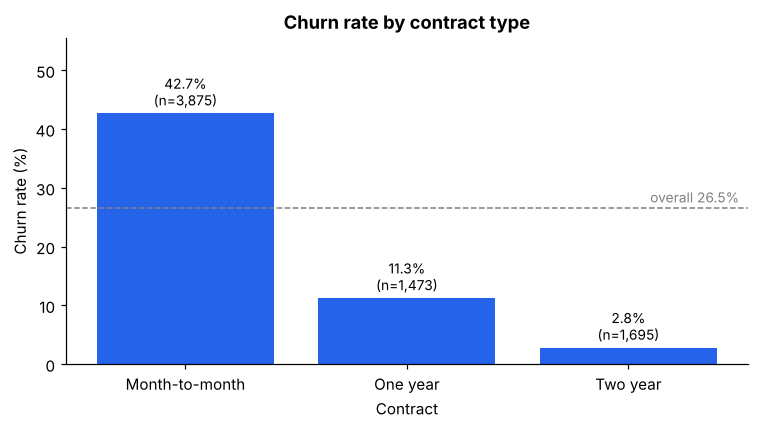

In [9]:
contract_order = ["Month-to-month", "One year", "Two year"]
by_contract = churn_table(df, "contract", contract_order)
display(by_contract.style.format({"churn_rate": "{:.1%}"}))
bar_chart(by_contract, "Churn rate by contract type", "Contract", "01_churn_by_contract.png")

### 2b. By tenure band

Bands: 0–12, 13–24, 25–48 and 49–72 months. The first band includes the 11 tenure-0 customers.

,customers,churned,churn_rate
tenure_band,,,
0-12,2186,1037,47.4%
13-24,1024,294,28.7%
25-48,1594,325,20.4%
49-72,2239,213,9.5%


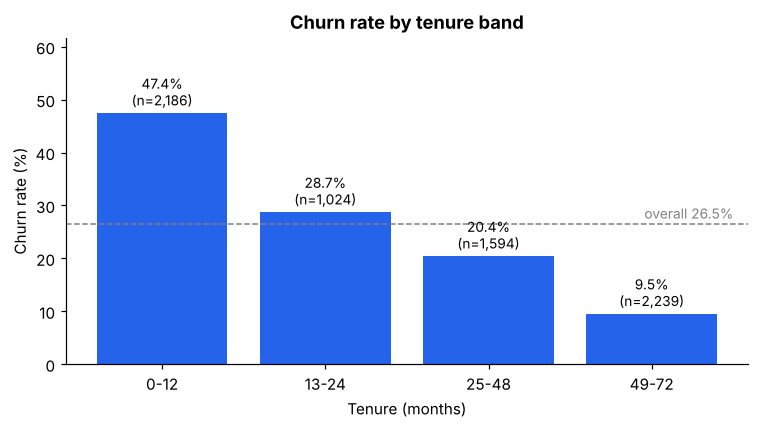

In [10]:
tenure_labels = ["0-12", "13-24", "25-48", "49-72"]
df["tenure_band"] = pd.cut(df["tenure_months"], bins=[-1, 12, 24, 48, 72],
                           labels=tenure_labels)
assert df["tenure_band"].isna().sum() == 0

by_tenure = churn_table(df, "tenure_band", tenure_labels)
display(by_tenure.style.format({"churn_rate": "{:.1%}"}))
bar_chart(by_tenure, "Churn rate by tenure band", "Tenure (months)", "02_churn_by_tenure.png")

### 2c. By internet service

,customers,churned,churn_rate
internet_service,,,
DSL,2421,459,19.0%
Fiber optic,3096,1297,41.9%
No,1526,113,7.4%


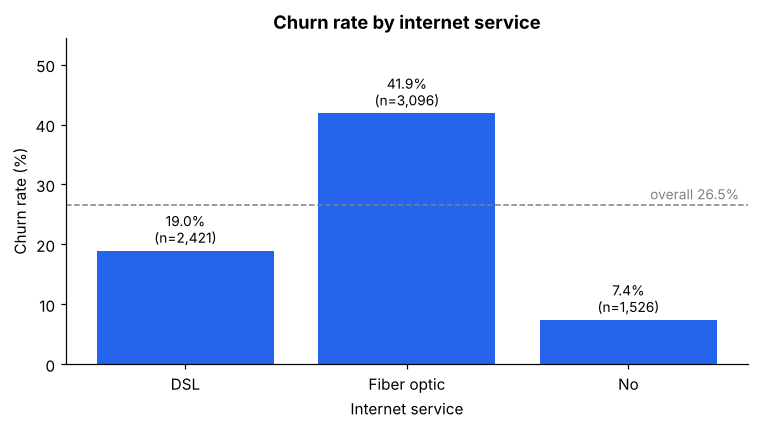

In [11]:
internet_order = ["DSL", "Fiber optic", "No"]
by_internet = churn_table(df, "internet_service", internet_order)
display(by_internet.style.format({"churn_rate": "{:.1%}"}))
bar_chart(by_internet, "Churn rate by internet service", "Internet service",
          "03_churn_by_internet.png")

### 2d. Contract × internet service

Highest-churn combination: Month-to-month + Fiber optic → 54.6% of 2,128 customers


customers churn_rate
contract internet_service  
Month-to-month Fiber optic 2128 54.6%
DSL 1223 32.2%
One year Fiber optic 539 19.3%
Month-to-month No 524 18.9%
One year DSL 570 9.3%
Two year Fiber optic 429 7.2%
One year No 364 2.5%
Two year DSL 628 1.9%
No 638 0.8%

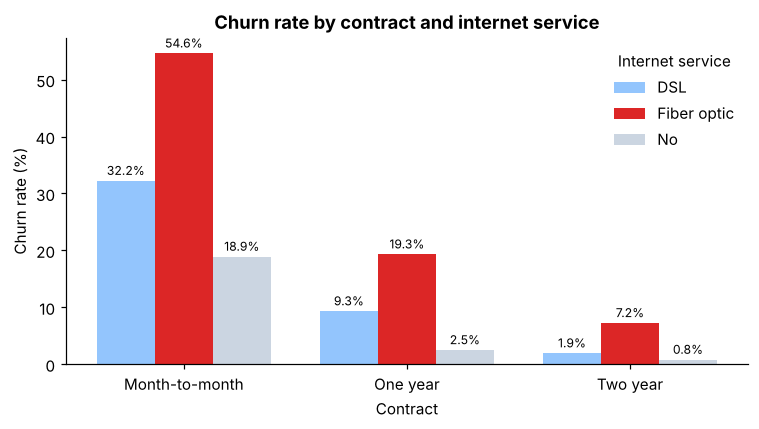

In [12]:
combo = (df.groupby(["contract", "internet_service"])["churned"]
           .agg(customers="size", churn_rate="mean")
           .sort_values("churn_rate", ascending=False))
display(combo.style.format({"churn_rate": "{:.1%}"}))

pivot = df.pivot_table(index="contract", columns="internet_service",
                       values="churned", aggfunc="mean").reindex(contract_order)[internet_order]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(contract_order))
w = 0.26
colors = ["#93c5fd", HIGHLIGHT, "#cbd5e1"]
for i, svc in enumerate(internet_order):
    bars = ax.bar(x + (i - 1) * w, pivot[svc] * 100, w, label=svc, color=colors[i])
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8)
ax.set_xticks(x, contract_order)
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Contract")
ax.set_title("Churn rate by contract and internet service")
ax.legend(title="Internet service", frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_churn_by_contract_internet.png", bbox_inches="tight")
plt.show()

top = combo.index[0]
print(f"Highest-churn combination: {top[0]} + {top[1]} "
      f"→ {combo.iloc[0]['churn_rate']:.1%} of {int(combo.iloc[0]['customers']):,} customers")

### 2e. Other notable patterns (context for the recommendation)

In [13]:
for col in ["payment_method", "online_security", "tech_support", "senior_citizen", "paperless_billing"]:
    t = churn_table(df, col).sort_values("churn_rate", ascending=False)
    print(f"\n{col}")
    print(t.assign(churn_rate=t["churn_rate"].map("{:.1%}".format)).to_string())


payment_method
                           customers  churned churn_rate
payment_method                                          
Electronic check                2365     1071      45.3%
Mailed check                    1612      308      19.1%
Bank transfer (automatic)       1544      258      16.7%
Credit card (automatic)         1522      232      15.2%

online_security
                     customers  churned churn_rate
online_security                                   
No                        3498     1461      41.8%
Yes                       2019      295      14.6%
No internet service       1526      113       7.4%

tech_support
                     customers  churned churn_rate
tech_support                                      
No                        3473     1446      41.6%
Yes                       2044      310      15.2%
No internet service       1526      113       7.4%

senior_citizen
                customers  churned churn_rate
senior_citizen                         

**Answers — Milestone 2**
- **Overall churn rate:** **26.5%** — just over 1 in 4 customers left last month.
- **Contract:** churn falls sharply as commitment rises — **42.7%** month-to-month, **11.3%** one-year, **2.8%** two-year. A month-to-month customer is roughly 15× as likely to leave as a two-year customer.
- **Tenure:** risk is concentrated early — **47.4%** in the first year (0–12 months), 28.7% at 13–24, 20.4% at 25–48 and just **9.5%** at 49–72 months. Customers who get through their first year mostly stay.
- **Internet service:** fibre-optic customers churn at **41.9%**, more than double DSL (19.0%); customers without internet churn at 7.4%.
- **Highest-risk combination:** **Month-to-month + Fiber optic — 54.6%** churn across 2,128 customers. More than half of the largest risky segment leaves.
- Also notable: customers paying by electronic check (45.3%) and those without online security or tech support (~42%) churn far more than average.

## 3. Is the difference real?

Compare average monthly charges for customers who left versus those who stayed.

In [14]:
churners = df.loc[df["churned"] == 1, "monthly_charges"]
stayers = df.loc[df["churned"] == 0, "monthly_charges"]

summary = pd.DataFrame({
    "customers": [len(churners), len(stayers)],
    "mean_monthly": [churners.mean(), stayers.mean()],
    "median_monthly": [churners.median(), stayers.median()],
    "std": [churners.std(), stayers.std()],
}, index=["Churned", "Stayed"]).round(2)
display(summary)
diff = churners.mean() - stayers.mean()
print(f"Churners pay ${diff:.2f} more per month on average "
      f"({diff / stayers.mean():.1%} more than stayers).")

Churners pay $13.18 more per month on average (21.5% more than stayers).


,customers,mean_monthly,median_monthly,std
Churned,1869,74.44,79.65,24.67
Stayed,5174,61.27,64.43,31.09


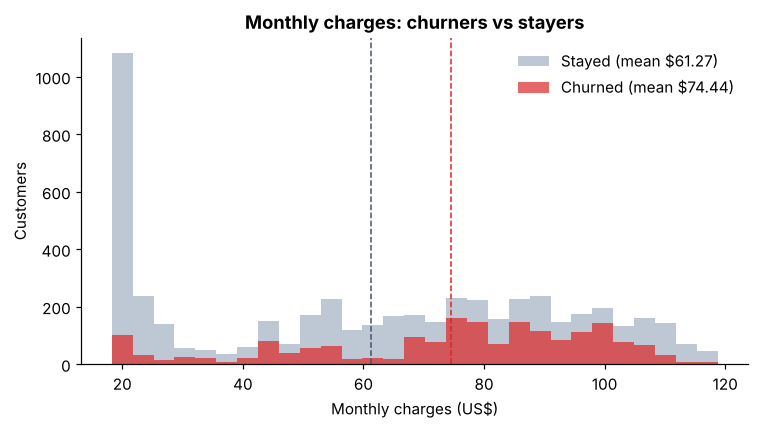

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(df["monthly_charges"].min(), df["monthly_charges"].max(), 30)
ax.hist(stayers, bins=bins, alpha=0.6, label=f"Stayed (mean ${stayers.mean():.2f})", color="#94a3b8")
ax.hist(churners, bins=bins, alpha=0.7, label=f"Churned (mean ${churners.mean():.2f})", color=HIGHLIGHT)
ax.axvline(stayers.mean(), color="#475569", ls="--", lw=1)
ax.axvline(churners.mean(), color=HIGHLIGHT, ls="--", lw=1)
ax.set_title("Monthly charges: churners vs stayers")
ax.set_xlabel("Monthly charges (US$)")
ax.set_ylabel("Customers")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_monthly_charges_distribution.png", bbox_inches="tight")
plt.show()

**Hypotheses**
- H₀: churners and stayers have the same mean monthly charge.
- H₁: the means differ (two-sided).

I use **Welch's t-test** (`equal_var=False`) because the two groups have different sizes and different spreads; it does not assume equal variances. With thousands of customers per group, the means are approximately normal (central limit theorem) even though monthly charges themselves are not normally distributed.

In [16]:
t_stat, p_value = stats.ttest_ind(churners, stayers, equal_var=False)
print(f"Welch t-statistic: {t_stat:.2f}")
print(f"p-value:           {p_value:.2e}")

# Effect size (Cohen's d with pooled SD) — how big, not just whether
pooled_sd = np.sqrt(((len(churners) - 1) * churners.var() + (len(stayers) - 1) * stayers.var())
                    / (len(churners) + len(stayers) - 2))
cohens_d = diff / pooled_sd

# 95% confidence interval for the difference (Welch)
se = np.sqrt(churners.var() / len(churners) + stayers.var() / len(stayers))
dof = se**4 / ((churners.var() / len(churners))**2 / (len(churners) - 1)
               + (stayers.var() / len(stayers))**2 / (len(stayers) - 1))
t_crit = stats.t.ppf(0.975, dof)
print(f"Difference in means: ${diff:.2f}  (95% CI ${diff - t_crit*se:.2f} to ${diff + t_crit*se:.2f})")
print(f"Cohen's d:          {cohens_d:.2f}")

Welch t-statistic: 18.41
p-value:           8.59e-73
Difference in means: $13.18  (95% CI $11.77 to $14.58)
Cohen's d:          0.45


**Answers — Milestone 3**
- **How charges differ:** churners pay on average **\$74.44/month** versus **\$61.27** for stayers — about **\$13.18 more** (95% CI roughly \$11.8 to \$14.6). Their median is even higher (\$79.65 vs \$64.43), reflecting that many churners are on fibre plans.
- **What the p-value tells us:** p ≈ 8.6 × 10⁻⁷³. If churners and stayers really had the same average charge, a gap this large would essentially never appear by chance in samples this size. So the difference is real, not noise.
- **What it does *not* tell us:**
  - It says nothing about **cause**. Higher bills may not drive churn — fibre customers pay more *and* churn more, and many churners are new month-to-month customers. Price could be a symptom of plan type rather than the reason people leave.
  - It says nothing about **how big or important** the effect is. With 7,000 rows, even tiny differences get tiny p-values; the effect size (Cohen's d ≈ 0.45, moderate) and the \$13 gap are what matter for the business.
  - It is not the probability that the null hypothesis is true, and it does not say an individual high-paying customer will churn.

## 4. Predict churn

### Feature set and leakage control
- **Dropped `customer_id`** — an identifier, not information about behaviour.
- **Dropped `churn` and `churned`** from the features — they are the target.
- **Dropped `tenure_band`** — it was created for the EDA and duplicates `tenure_months`.
- **One-hot encoding is fitted on the training set only**, inside a scikit-learn `Pipeline`, so nothing about the test set leaks into training. `handle_unknown="ignore"` protects against categories that only appear at prediction time.
- The logistic regression gets **scaled numeric features** (it needs comparable scales to converge well); the tree does not need scaling.

All remaining columns describe the customer *as of the snapshot*. Note that `tenure_months` and `total_charges` are measured at the same time as churn, which is acceptable here because the business will score current customers with the same fields.

In [17]:
target = "churned"
drop_cols = ["customer_id", "churn", "churned", "tenure_band"]
X = df.drop(columns=drop_cols)
y = df[target]

numeric_cols = ["tenure_months", "monthly_charges", "total_charges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]
# senior_citizen is 0/1 already; treat it as categorical for consistent encoding
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"\nTrain: {len(X_train):,} rows, churn rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} rows, churn rate {y_test.mean():.1%}")

Numeric: ['tenure_months', 'monthly_charges', 'total_charges']
Categorical: ['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method']

Train: 5,634 rows, churn rate 26.5%
Test:  1,409 rows, churn rate 26.5%


Stratifying keeps the 26.5% churn rate identical in both sets, so test scores aren't distorted by an unlucky split.

In [18]:
def make_preprocessor(scale_numeric):
    num = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("num", num, numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

log_reg = Pipeline([
    ("prep", make_preprocessor(scale_numeric=True)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

tree = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
])

log_reg.fit(X_train, y_train)
tree.fit(X_train, y_train)

n_features = len(log_reg.named_steps["prep"].get_feature_names_out())
print(f"Features after one-hot encoding: {n_features}")

Features after one-hot encoding: 46


### Baseline: predict that nobody leaves

In [19]:
baseline_pred = np.zeros_like(y_test)
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_auc = roc_auc_score(y_test, np.zeros(len(y_test)))  # constant score → 0.5
print(f"Baseline accuracy: {baseline_acc:.1%}")
print(f"Baseline ROC-AUC:  {baseline_auc:.3f}")
print(f"Baseline recall:   {recall_score(y_test, baseline_pred):.1%}  (catches no churners)")

Baseline accuracy: 73.5%
Baseline ROC-AUC:  0.500
Baseline recall:   0.0%  (catches no churners)


In [20]:
results = []
for name, model in [("Logistic regression", log_reg), ("Decision tree (depth 4)", tree)]:
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "recall_churners": recall_score(y_test, pred),
    })
results.insert(0, {"model": "Baseline: nobody leaves", "accuracy": baseline_acc,
                   "roc_auc": baseline_auc, "recall_churners": 0.0})
results = pd.DataFrame(results).set_index("model")
display(results.style.format({"accuracy": "{:.1%}", "roc_auc": "{:.3f}",
                              "recall_churners": "{:.1%}"}))

,accuracy,roc_auc,recall_churners
model,,,
Baseline: nobody leaves,73.5%,0.500,0.0%
Logistic regression,80.6%,0.842,55.9%
Decision tree (depth 4),79.2%,0.829,45.2%


Check for overfitting — compare train and test ROC-AUC:

In [21]:
for name, model in [("Logistic regression", log_reg), ("Decision tree", tree)]:
    tr = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    te = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(f"{name:20s} train AUC {tr:.3f} | test AUC {te:.3f} | gap {tr - te:+.3f}")

Logistic regression  train AUC 0.849 | test AUC 0.842 | gap +0.007
Decision tree        train AUC 0.840 | test AUC 0.829 | gap +0.011


The train/test gaps are small, so neither model is overfitting; `max_depth=4` keeps the tree simple.

### Cross-validation on the training set

One test split can be lucky or unlucky. 5-fold stratified cross-validation on the **training data only** (the test set stays untouched) shows how stable the scores are.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in [("Logistic regression", log_reg), ("Decision tree", tree)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:20s} CV ROC-AUC {scores.mean():.3f} ± {scores.std():.3f}  "
          f"(folds: {', '.join(f'{s:.3f}' for s in scores)})")

Logistic regression  CV ROC-AUC 0.846 ± 0.013  (folds: 0.848, 0.825, 0.842, 0.863, 0.853)
Decision tree        CV ROC-AUC 0.826 ± 0.009  (folds: 0.820, 0.814, 0.827, 0.832, 0.839)


Fold-to-fold variation is small and the cross-validated means sit close to the test-set scores, so the results are not an accident of one split.

### Decision tree: recall and confusion matrix

              precision    recall  f1-score   support

      Stayed      0.822     0.915     0.866      1035
     Churned      0.658     0.452     0.536       374

    accuracy                          0.792      1409
   macro avg      0.740     0.683     0.701      1409
weighted avg      0.778     0.792     0.778      1409

Real churners in test set: 374
Caught by the tree:        169  → recall 45.2%
Missed:                    205
False alarms:              88


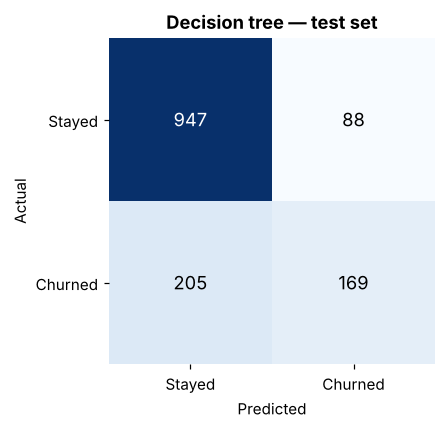

In [23]:
tree_pred = tree.predict(X_test)
cm = confusion_matrix(y_test, tree_pred)
tn, fp, fn, tp = cm.ravel()
print(classification_report(y_test, tree_pred, target_names=["Stayed", "Churned"], digits=3))
print(f"Real churners in test set: {tp + fn}")
print(f"Caught by the tree:        {tp}  → recall {tp / (tp + fn):.1%}")
print(f"Missed:                    {fn}")
print(f"False alarms:              {fp}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks([0, 1], ["Stayed", "Churned"])
ax.set_yticks([0, 1], ["Stayed", "Churned"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Decision tree — test set")
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_tree_confusion_matrix.png", bbox_inches="tight")
plt.show()

### Choosing a threshold

`predict()` uses a 0.5 cut-off, which treats a missed churner and a false alarm as equally costly. For retention they aren't: a missed churner loses a whole customer, while a false alarm costs one offer. Lowering the threshold catches more churners at the price of more offers sent. (Shown for the logistic regression, whose probabilities feed the risk bands.)

In [24]:
lr_proba_test = log_reg.predict_proba(X_test)[:, 1]
rows = []
for thr in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (lr_proba_test >= thr).astype(int)
    rows.append({"threshold": thr,
                 "customers_flagged": int(pred.sum()),
                 "recall": recall_score(y_test, pred),
                 "precision": precision_score(y_test, pred)})
thr_table = pd.DataFrame(rows).set_index("threshold")
display(thr_table.style.format({"recall": "{:.1%}", "precision": "{:.1%}"})
                 .format_index("{:.1f}"))

,customers_flagged,recall,precision
threshold,,,
0.2,686,85.8%,46.8%
0.3,543,75.4%,51.9%
0.4,440,66.8%,56.8%
0.5,318,55.9%,65.7%
0.6,209,40.1%,71.8%


The right threshold is a budget decision: moving from 0.5 to 0.3 flags 543 customers instead of 318 and raises recall from 55.9% to 75.4%, but precision drops from 65.7% to 51.9%, so more of the people flagged would have stayed anyway. The risk bands in Milestone 5 turn this into tiers instead of one yes/no cut-off.

### Which feature does the tree rely on most?

,importance
contract_Month-to-month,0.554
internet_service_Fiber optic,0.176
tenure_months,0.158
payment_method_Electronic check,0.030
tech_support_No,0.023
monthly_charges,0.021
total_charges,0.020
contract_Two year,0.012
online_security_No,0.005
contract_One year,0.001


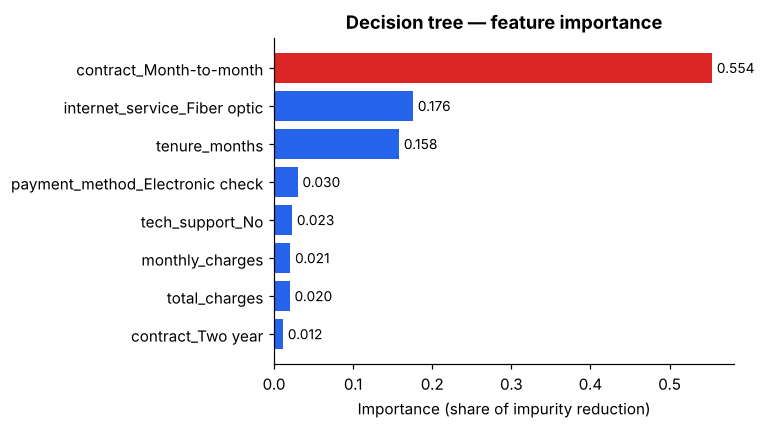

In [25]:
feat_names = tree.named_steps["prep"].get_feature_names_out()
importances = (pd.Series(tree.named_steps["model"].feature_importances_, index=feat_names)
                 .rename(lambda s: s.replace("num__", "").replace("cat__", ""))
                 .sort_values(ascending=False))
top_imp = importances[importances > 0]
display(top_imp.to_frame("importance").style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7, 4))
plot_data = top_imp.head(8)[::-1]
colors = [HIGHLIGHT if i == len(plot_data) - 1 else BAR for i in range(len(plot_data))]
bars = ax.barh(plot_data.index, plot_data.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_title("Decision tree — feature importance")
ax.set_xlabel("Importance (share of impurity reduction)")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_tree_feature_importance.png", bbox_inches="tight")
plt.show()

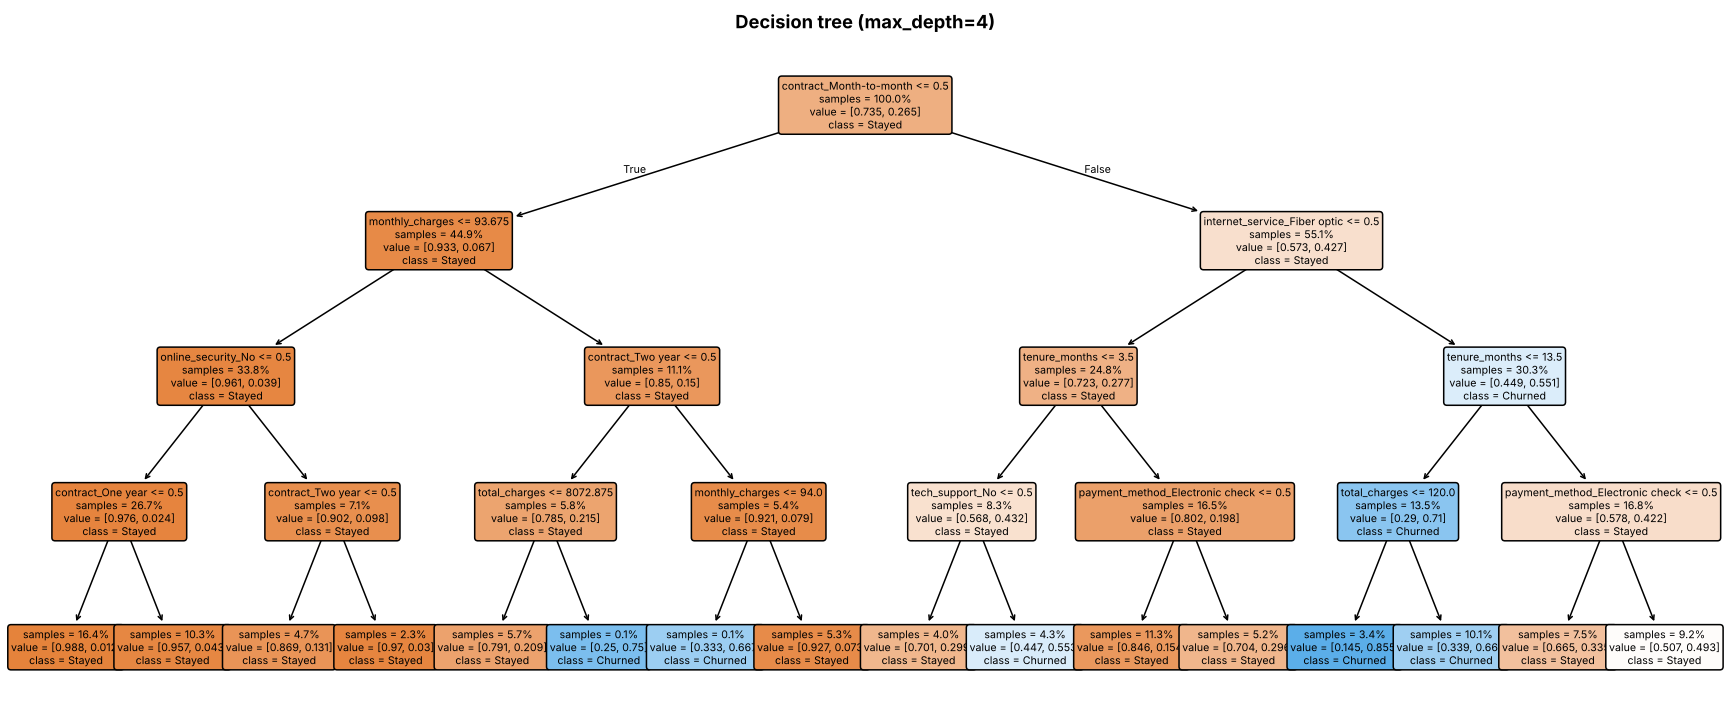

In [26]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree.named_steps["model"],
          feature_names=[n.replace("num__", "").replace("cat__", "") for n in feat_names],
          class_names=["Stayed", "Churned"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=7, ax=ax)
ax.set_title("Decision tree (max_depth=4)")
fig.savefig(FIG_DIR / "08_decision_tree.png", bbox_inches="tight")
plt.show()

### Logistic regression: which features push risk up or down?

Coefficients are on scaled numerics / one-hot categories, so they show direction and relative strength (log-odds).

In [27]:
lr_coef = (pd.Series(log_reg.named_steps["model"].coef_[0],
                     index=log_reg.named_steps["prep"].get_feature_names_out())
             .rename(lambda s: s.replace("num__", "").replace("cat__", "")))
coef_view = pd.concat([lr_coef.nlargest(6), lr_coef.nsmallest(6)])
display(coef_view.to_frame("coefficient (log-odds)").style.format("{:+.3f}"))

,coefficient (log-odds)
internet_service_Fiber optic,+0.648
contract_Month-to-month,+0.586
total_charges,+0.533
streaming_movies_Yes,+0.212
streaming_tv_Yes,+0.212
payment_method_Electronic check,+0.206
tenure_months,-1.255
contract_Two year,-0.759
internet_service_DSL,-0.644
monthly_charges,-0.601


**Answers — Milestone 4**
- **Models vs baseline:** "nobody leaves" already scores **73.5% accuracy** on the test set — because 73.5% of customers stay — while catching zero churners. The logistic regression reaches about **80.6% accuracy / 0.842 ROC-AUC**, and the depth-4 tree about **79.2% / 0.829**. Both are clearly better than the baseline's 0.5 AUC.
- **Accuracy or ROC-AUC?** **ROC-AUC is the more useful measure here.** With an imbalanced target, accuracy rewards ignoring churners (the useless baseline gets 73.5%). ROC-AUC measures how well the model **ranks** customers by risk — exactly what the retention team needs to spend a limited budget on the riskiest customers first — and it doesn't depend on a single threshold. In practice we'd also watch recall/precision at the threshold we act on.
- **Tree recall:** the tree catches **45.2% of real churners** (169 of 374) at the default 0.5 threshold, with 88 false alarms. That's a long way from the baseline's 0%, but more than half of leavers are still missed — lowering the threshold would catch more at the cost of more false alarms.
- **Most important feature:** the tree relies most on **`contract_Month-to-month`** (0.554, over half of total importance), followed by `internet_service_Fiber optic` (0.176) and `tenure_months` (0.158). That matches Milestone 2 exactly: contract type was the strongest pattern, then fibre and short tenure. The logistic regression agrees — fibre, month-to-month and electronic-check payment raise risk; longer tenure and two-year contracts lower it. (Its *negative* coefficient on `monthly_charges` doesn't contradict Milestone 3: charges are strongly tied to fibre and the add-ons, so once those are in the model, the leftover effect of price shifts. Individual coefficients of correlated features shouldn't be read as causal.)

## 5. Risk bands and recommendation

Turn the logistic regression's churn probabilities into bands the retention team can act on:

| Band | Probability | Meaning |
|---|---|---|
| **Low** | < 0.30 | Below the overall churn rate — no offer needed |
| **Medium** | 0.30 – 0.60 | Elevated risk — lighter-touch offer |
| **High** | ≥ 0.60 | Most likely to leave — target first |

0.30 sits just above the 26.5% base rate, so "low" means "below-average risk".

In [28]:
test_scored = X_test.copy()
test_scored["churned"] = y_test
test_scored["churn_probability"] = log_reg.predict_proba(X_test)[:, 1]
test_scored["risk_band"] = pd.cut(test_scored["churn_probability"],
                                  bins=[0, 0.30, 0.60, 1.0],
                                  labels=["Low", "Medium", "High"], include_lowest=True)

bands = (test_scored.groupby("risk_band", observed=True)
            .agg(customers=("churned", "size"),
                 actual_churners=("churned", "sum"),
                 actual_churn_rate=("churned", "mean"),
                 avg_predicted=("churn_probability", "mean"),
                 avg_monthly_charges=("monthly_charges", "mean")))
bands["share_of_customers"] = bands["customers"] / bands["customers"].sum()
bands["share_of_all_churners"] = bands["actual_churners"] / bands["actual_churners"].sum()
display(bands.style.format({"actual_churn_rate": "{:.1%}", "avg_predicted": "{:.1%}",
                            "avg_monthly_charges": "${:.2f}", "share_of_customers": "{:.1%}",
                            "share_of_all_churners": "{:.1%}"}))

,customers,actual_churners,actual_churn_rate,avg_predicted,avg_monthly_charges,share_of_customers,share_of_all_churners
risk_band,,,,,,,
Low,866,92,10.6%,9.4%,$56.08,61.5%,24.6%
Medium,334,132,39.5%,45.1%,$73.90,23.7%,35.3%
High,209,150,71.8%,69.4%,$81.59,14.8%,40.1%


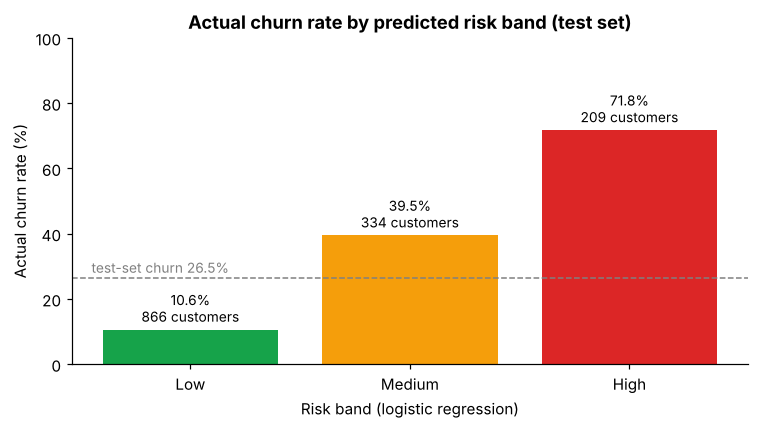

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
band_colors = ["#16a34a", "#f59e0b", HIGHLIGHT]
bars = ax.bar(bands.index.astype(str), bands["actual_churn_rate"] * 100, color=band_colors)
ax.bar_label(bars, labels=[f"{r:.1%}\n{n:,} customers" for r, n in
                           zip(bands["actual_churn_rate"], bands["customers"])],
             padding=3, fontsize=9)
ax.axhline(y_test.mean() * 100, color="grey", ls="--", lw=1)
ax.text(-0.45, y_test.mean() * 100 + 1.5, f"test-set churn {y_test.mean():.1%}",
        ha="left", color="grey", fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Actual churn rate by predicted risk band (test set)")
ax.set_xlabel("Risk band (logistic regression)")
ax.set_ylabel("Actual churn rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_risk_bands.png", bbox_inches="tight")
plt.show()

**Who is in the high-risk band?** Profile it against the other bands to design the offer.

In [30]:
profile_cols = ["contract", "internet_service", "payment_method", "online_security", "tech_support"]
for col in profile_cols:
    share = (pd.crosstab(test_scored["risk_band"], test_scored[col], normalize="index") * 100).round(1)
    print(f"\n% of each band by {col}")
    print(share.to_string())

print("\nMedian tenure (months) by band:")
print(test_scored.groupby("risk_band", observed=True)["tenure_months"].median().to_string())


% of each band by contract
contract   Month-to-month  One year  Two year
risk_band                                    
Low                  29.0      32.2      38.8
Medium               93.7       6.3       0.0
High                100.0       0.0       0.0

% of each band by internet_service
internet_service   DSL  Fiber optic    No
risk_band                                
Low               40.9         23.2  35.9
Medium            35.6         64.1   0.3
High               5.3         94.7   0.0

% of each band by payment_method
payment_method  Bank transfer (automatic)  Credit card (automatic)  Electronic check  Mailed check
risk_band                                                                                         
Low                                  27.4                     27.7              16.6          28.3
Medium                               15.0                     16.5              49.7          18.9
High                                  6.2                      6.7

In [31]:
# Save the scored test set so the risk list can be inspected outside the notebook
out = df.loc[test_scored.index, ["customer_id"]].join(
    test_scored[["contract", "internet_service", "tenure_months", "monthly_charges",
                 "churn_probability", "risk_band", "churned"]])
out = out.sort_values("churn_probability", ascending=False)
(ROOT / "reports").mkdir(exist_ok=True)
out.to_csv(ROOT / "reports" / "test_set_risk_scores.csv", index=False)
out.head(10)

,customer_id,contract,internet_service,tenure_months,monthly_charges,churn_probability,risk_band,churned
3380,5178-LMXOP,Month-to-month,Fiber optic,1,95.10,0.855041,High,1
6866,0295-PPHDO,Month-to-month,Fiber optic,1,95.45,0.831959,High,1
2631,6861-XWTWQ,Month-to-month,Fiber optic,7,99.25,0.828618,High,1
6365,8884-ADFVN,Month-to-month,Fiber optic,7,101.95,0.822047,High,1
4585,1069-XAIEM,Month-to-month,Fiber optic,1,85.05,0.819059,High,1
3346,2545-EBUPK,Month-to-month,Fiber optic,2,84.05,0.817939,High,0
2797,6023-YEBUP,Month-to-month,Fiber optic,3,100.95,0.817530,High,1
3727,9057-SIHCH,Month-to-month,Fiber optic,3,96.60,0.817346,High,1
6894,1400-MMYXY,Month-to-month,Fiber optic,3,105.90,0.816327,High,1
935,6630-UJZMY,Month-to-month,Fiber optic,4,83.25,0.812378,High,0


**Answers — Milestone 5**
- **Band sizes and actual churn (1,409 test customers):**
  - **High** (≥ 0.60): **209 customers (14.8%)** — **71.8%** actually churned (150 customers).
  - **Medium** (0.30–0.60): **334 customers (23.7%)** — **39.5%** churned (132).
  - **Low** (< 0.30): **866 customers (61.5%)** — only **10.6%** churned (92).

  The bands line up with reality: average predicted risk (69%, 45%, 9%) tracks actual churn closely, so the probabilities can be trusted for ranking. High + Medium together are **38.5% of customers but 75.4% of all churners**.
- **Who gets the budget first:** the **High** band — **100% month-to-month, 95% fibre-optic, median tenure 4 months**, 79% paying by electronic check, and almost none with online security (98% without) or tech support (97% without). Then Medium. Stop the blanket discount for the Low band, where ~90% stay anyway.
- **Offer to test:** a **contract-upgrade offer** for High-risk customers — e.g. a discount or free add-on (online security / tech support) in exchange for moving to a one-year contract — because contract length is the strongest lever in the data. Run it as an **A/B test**: randomly hold back part of the High band as a control group, so we measure how many customers the offer actually *saves*, not just how many accepted.
- **What a one-month snapshot can't tell us:**
  - **Why** customers leave — no complaints, network quality, call/data usage or competitor pricing.
  - **Whether an offer will work** — the model predicts who leaves, not who can be *persuaded* to stay (uplift). Some high-risk customers will leave regardless.
  - **Trends or timing** — one month only, so no seasonality, no change in behaviour before leaving, and no way to know whether the model still holds next quarter.
  - **Customer value** — no margin or lifetime value, so we can't yet say which saved customers are worth the cost of the offer.
  - The data is a fictional IBM sample in US dollars; results should be re-validated on Simu Connect's real customers before any rollout.

The full recommendation is in [`reports/retention_note.md`](../reports/retention_note.md).